In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shahliza27/ur-fall-detection-dataset")

print("Path to dataset files:", path)

100%|██████████| 4.18G/4.18G [01:54<00:00, 39.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1


In [13]:

import os
import cv2
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve

root = Path(path) / "UR_fall_detection_dataset_cam0_rgb"

print("Dataset path:", root)
print("Dataset exists:", root.exists())

images = list(root.rglob("*.png")) + list(root.rglob("*.PNG"))

print("Total images:", len(images))
print("First 20 images:")

for img in images[:20]:
    print(img)


Dataset path: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb
Dataset exists: True
Total images: 11936
First 20 images:
/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-04-cam0-rgb/fall-04-cam0-rgb-075.png
/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-04-cam0-rgb/fall-04-cam0-rgb-024.png
/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-04-cam0-rgb/fall-04-cam0-rgb-032.png
/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-04-cam0-rgb/fall-04-cam0-rgb-049.png
/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-04-cam0-rgb/fall-04-cam0-rgb-082.png
/root/.cache/kagglehub/datas

In [14]:

from collections import Counter

print("Main folders:")

for item in sorted(root.iterdir()):
    if item.is_dir():
        print(item.name, "| Images:", len(list(item.rglob("*.png"))))

print("\nFolder structure:")

for current, dirs, files in os.walk(root):
    level = len(Path(current).relative_to(root).parts)

    if level <= 3:
        png_files = [f for f in files if f.lower().endswith(".png")]
        print("  " * level + Path(current).name, "|", len(png_files), "images")

        for f in png_files[:3]:
            print("  " * (level + 1) + f)


Main folders:
adl-01-cam0-rgb | Images: 150
adl-02-cam0-rgb | Images: 180
adl-03-cam0-rgb | Images: 180
adl-04-cam0-rgb | Images: 150
adl-05-cam0-rgb | Images: 180
adl-06-cam0-rgb | Images: 230
adl-07-cam0-rgb | Images: 180
adl-08-cam0-rgb | Images: 180
adl-09-cam0-rgb | Images: 150
adl-10-cam0-rgb | Images: 300
adl-11-cam0-rgb | Images: 300
adl-12-cam0-rgb | Images: 250
adl-13-cam0-rgb | Images: 265
adl-14-cam0-rgb | Images: 235
adl-15-cam0-rgb | Images: 275
adl-16-cam0-rgb | Images: 240
adl-17-cam0-rgb | Images: 230
adl-18-cam0-rgb | Images: 265
adl-19-cam0-rgb | Images: 250
adl-20-cam0-rgb | Images: 270
adl-21-cam0-rgb | Images: 280
adl-22-cam0-rgb | Images: 240
adl-23-cam0-rgb | Images: 220
adl-24-cam0-rgb | Images: 70
adl-25-cam0-rgb | Images: 110
adl-26-cam0-rgb | Images: 95
adl-27-cam0-rgb | Images: 100
adl-28-cam0-rgb | Images: 85
adl-29-cam0-rgb | Images: 125
adl-30-cam0-rgb | Images: 400
adl-31-cam0-rgb | Images: 250
adl-32-cam0-rgb | Images: 200
adl-33-cam0-rgb | Images: 200

Dataset shape: (70, 16, 112, 112, 3)
Labels shape: (70,)
ADL sequences: 40
Fall sequences: 30

Training: (49, 16, 112, 112, 3)
Validation: (10, 16, 112, 112, 3)
Testing: (11, 16, 112, 112, 3)


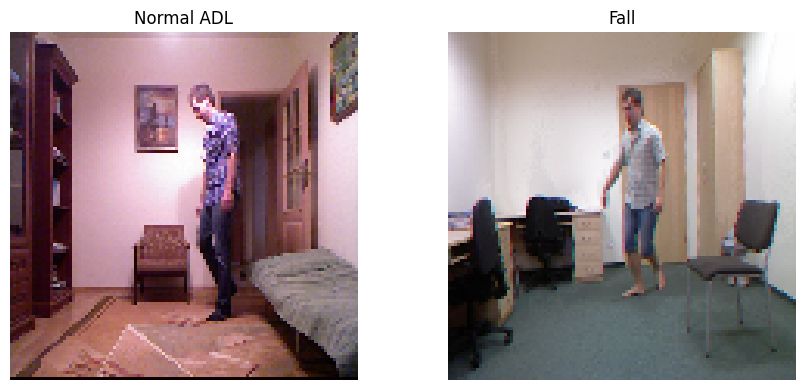

In [15]:

import re
import numpy as np
import cv2
from pathlib import Path
from sklearn.model_selection import train_test_split

IMG_SIZE = 112
NUM_FRAMES = 16
SEED = 42

X_data = []
y_data = []
sequence_names = []

for folder in sorted(root.iterdir()):
    if not folder.is_dir():
        continue

    name = folder.name.lower()

    if name.startswith("adl-"):
        label = 0
    elif name.startswith("fall-"):
        label = 1
    else:
        continue

    files = sorted(
        folder.glob("*.png"),
        key=lambda f: int(re.search(r"-(\d+)\.png$", f.name).group(1))
        if re.search(r"-(\d+)\.png$", f.name) else 0
    )

    if len(files) < NUM_FRAMES:
        continue

    indices = np.linspace(0, len(files)-1, NUM_FRAMES).astype(int)
    frames = []
    valid = True

    for idx in indices:
        image = cv2.imread(str(files[idx]))

        if image is None:
            valid = False
            break

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        frames.append(image)

    if valid and len(frames) == NUM_FRAMES:
        X_data.append(np.array(frames, dtype=np.uint8))
        y_data.append(label)
        sequence_names.append(name)

X = np.array(X_data, dtype=np.uint8)
y = np.array(y_data, dtype=np.int32)
sequence_names = np.array(sequence_names)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("ADL sequences:", np.sum(y == 0))
print("Fall sequences:", np.sum(y == 1))

indices = np.arange(len(X))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=y
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=y[temp_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, label, title in zip(axes, [0, 1], ["Normal ADL", "Fall"]):
    idx = np.where(y == label)[0][0]
    ax.imshow(X[idx][NUM_FRAMES // 2])
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 16, 112, 112,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_5 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,977 (308.50 KB)

 Trainable params: 78,977 (308.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 23s 776ms/step - accuracy: 0.5306 - auc: 0.5026 - loss: 0.6919 - val_accuracy: 0.6000 - val_auc: 0.2917 - val_loss: 0.6905 - learning_rate: 1.0000e-04
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.5714 - auc: 0.5102 - loss: 0.6936 - val_accuracy: 0.6000 - val_auc: 0.6667 - val_loss: 0.6897 - learning_rate: 1.0000e-04
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.4082 - auc: 0.3767 - loss: 0.6977 - val_accuracy: 0.6000 - val_auc: 0.7500 - val_loss: 0.6883 - learning_rate: 1.0000e-04
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.5918 - auc: 0.5816 - loss: 0.6901 - val_accuracy: 0.7000 - val_auc: 0.8333 - val_loss: 0.6867 - learning_rate: 1.0000e-04
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.6939 - auc: 0.7024 - loss: 0.6847 - val_accuracy: 0.6000 - val_auc: 0.8333 - val_loss: 0.6858 - learning_rate: 1.0000e-04
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 

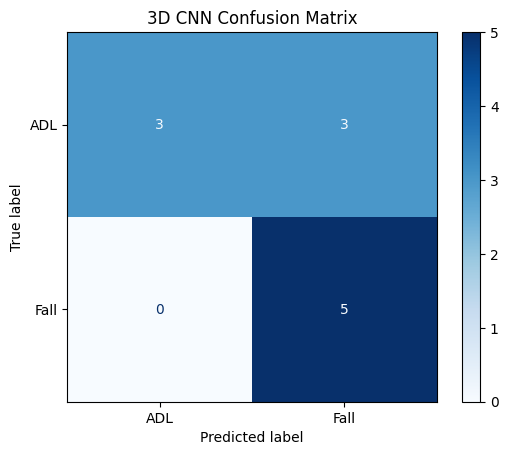

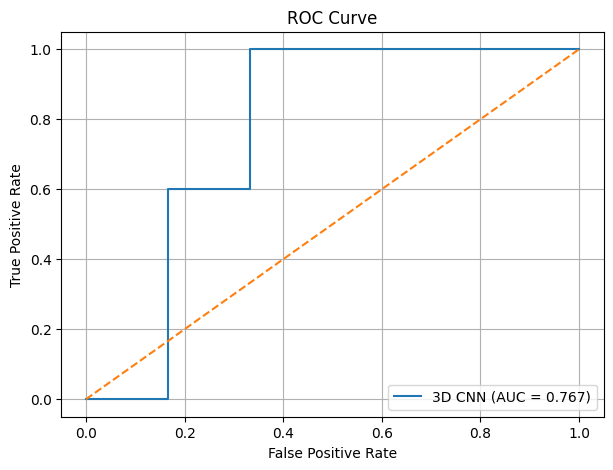

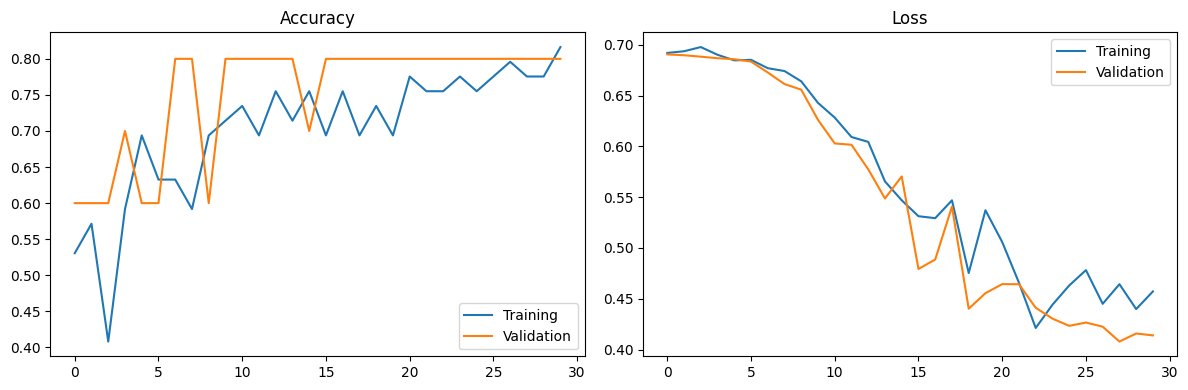

Model saved successfully.


In [16]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve

BATCH_SIZE = 4
EPOCHS = 30

tf.random.set_seed(42)

def augment(video, label):
    video = tf.cast(video, tf.float32)
    video = tf.image.random_flip_left_right(video)
    return video, label

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train), seed=42)
train_ds = train_ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv3D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling3D((1, 2, 2)),
    tf.keras.layers.Conv3D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling3D((2, 2, 2)),
    tf.keras.layers.Conv3D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling3D((2, 2, 2)),
    tf.keras.layers.GlobalAveragePooling3D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", patience=3, factor=0.5
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print("\nFINAL RESULTS")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall / Sensitivity:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("AUROC:", round(auc, 4))

print("\nClassification Report")
print(classification_report(
    y_test, y_pred,
    target_names=["ADL", "Fall"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["ADL", "Fall"]
).plot(cmap="Blues", values_format="d")

plt.title("3D CNN Confusion Matrix")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"3D CNN (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.show()

model.save("fall_detection_3dcnn.keras")
print("Model saved successfully.")


In [17]:

print("Model:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("AUROC:", auc)


Model: sequential_1
Input shape: (None, 16, 112, 112, 3)
Output shape: (None, 1)
Training samples: 49
Validation samples: 10
Testing samples: 11
Accuracy: 0.7272727272727273
Precision: 0.625
Recall: 1.0
F1 Score: 0.7692307692307693
AUROC: 0.7666666666666667


In [18]:

from google.colab import files

model.save("fall_detection_3dcnn.keras")
files.download("fall_detection_3dcnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>